# Certamen 1 · Ensambles, costo de clasificación y umbral óptimo
**Base de datos:** Health Insurance Cross Sell Prediction (Kaggle) · **Grupo:** 15

Del dato a la decisión: comparamos 5 modelos × 2 estrategias de desbalance, elegimos el mejor por CV y traducimos sus errores a dinero para encontrar el umbral de decisión que minimiza el costo.

**Estructura:** 1. Problema y base · 2. Exploración y pipeline · 3. Etapa A (SMOTE) · 4. Etapa B (pesos) · 5. Tabla de 10 combinaciones · 6. Matriz de costos · 7. Umbral teórico, empírico y ahorro · 8. Sensibilidad · 9. Exportación para el dashboard (Streamlit).

## 1. Problema de negocio y base de datos

**Contexto.** Una aseguradora que ya vende seguros de salud quiere hacer *venta cruzada* de un **seguro de vehículo** a sus clientes. Llamar a cada cliente cuesta dinero (call center), pero no llamar a alguien que sí habría comprado significa perder una venta.

**Variable objetivo (`Response`)**: 1 = el cliente se interesa en el seguro de vehículo, 0 = no. Ya es binaria.

- **Falso positivo (FP):** llamamos a un cliente que no compra → se pierde el costo del contacto.
- **Falso negativo (FN):** no llamamos a un cliente que sí habría comprado → se pierde el margen de la venta.

**Fuente:** [Kaggle · Health Insurance Cross Sell Prediction](https://www.kaggle.com/datasets/anmolkumar/health-insurance-cross-sell-prediction). Usamos solo `train.csv`, porque `test.csv` no trae la variable objetivo; nuestra propia partición 80/20 hace de test.

In [1]:
# --- Librerias clasicas ---
import os, time, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Particion, validacion cruzada y busqueda de hiperparametros ---
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
# --- Preprocesamiento (todo ira DENTRO del pipeline para evitar fuga de datos) ---
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.base import clone
# --- Los 5 modelos obligatorios ---
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
# --- Metricas y umbral por costo ---
from sklearn.metrics import (f1_score, recall_score, precision_score, roc_auc_score, roc_curve,
                             confusion_matrix, make_scorer)
from sklearn.model_selection import TunedThresholdClassifierCV
# --- imblearn: Pipeline que acepta SMOTE como paso (se aplica solo al train de cada fold) ---
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
SEED = 42                      # semilla fija para particion, SMOTE, CV y modelos
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# Carpetas de salida (para subir todo a GitHub)
os.makedirs("resultados", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("dashboard_data", exist_ok=True)
print("CPUs disponibles:", os.cpu_count())

CPUs disponibles: 12


In [2]:
# Carga de datos: busca train.csv local; en Colab pide subirlo.
rutas = ["data/train.csv", "train.csv", "/content/train.csv"]
ruta = next((r for r in rutas if os.path.exists(r)), None)
if ruta is None:
    from google.colab import files   # solo funciona en Colab
    print("Sube train.csv (de la carpeta del zip de Kaggle)")
    files.upload()
    ruta = "train.csv"

df = pd.read_csv(ruta).drop(columns="id")
print("Registros:", f"{len(df):,}", "| Variables predictoras:", df.shape[1] - 1)
print("Clase minoritaria (Response=1):", f"{df.Response.mean():.2%}")
df.head()

Registros: 381,109 | Variables predictoras: 10
Clase minoritaria (Response=1): 12.26%


,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


**Ficha de la base** (cumple los mínimos del enunciado)

| Requisito | Mínimo | Nuestra base |
|---|---|---|
| Tamaño | > 100.000 | 381.109 registros |
| Variable objetivo | binaria | `Response` (0/1) |
| Desbalance | minoritaria entre 1% y 30% | ≈ 12,26% |
| Predictoras | ≥ 8 | 10 |
| Costo FP / FN | asignable | contacto comercial vs. venta perdida |

## 2. Exploración y pipeline

In [3]:
# Tipos de variables, nulos y duplicados
print(df.dtypes, "\n")
print("Nulos por columna:\n", df.isna().sum(), "\n")
print("Filas duplicadas:", df.duplicated().sum())
# Resumen estadistico de las variables numericas
df.describe().T

Gender                      str
Age                       int64
Driving_License           int64
Region_Code             float64
Previously_Insured        int64
Vehicle_Age                 str
Vehicle_Damage              str
Annual_Premium          float64
Policy_Sales_Channel    float64
Vintage                   int64
Response                  int64
dtype: object 

Nulos por columna:
 Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64 

Filas duplicadas: 269


,count,mean,std,min,25%,50%,75%,max
Age,381109.0,38.822584,15.511611,20.0,25.0,36.0,49.0,85.0
Driving_License,381109.0,0.997869,0.046110,0.0,1.0,1.0,1.0,1.0
Region_Code,381109.0,26.388807,13.229888,0.0,15.0,28.0,35.0,52.0
Previously_Insured,381109.0,0.458210,0.498251,0.0,0.0,0.0,1.0,1.0
Annual_Premium,381109.0,30564.389581,17213.155057,2630.0,24405.0,31669.0,39400.0,540165.0
Policy_Sales_Channel,381109.0,112.034295,54.203995,1.0,29.0,133.0,152.0,163.0
Vintage,381109.0,154.347397,83.671304,10.0,82.0,154.0,227.0,299.0
Response,381109.0,0.122563,0.327936,0.0,0.0,0.0,0.0,1.0


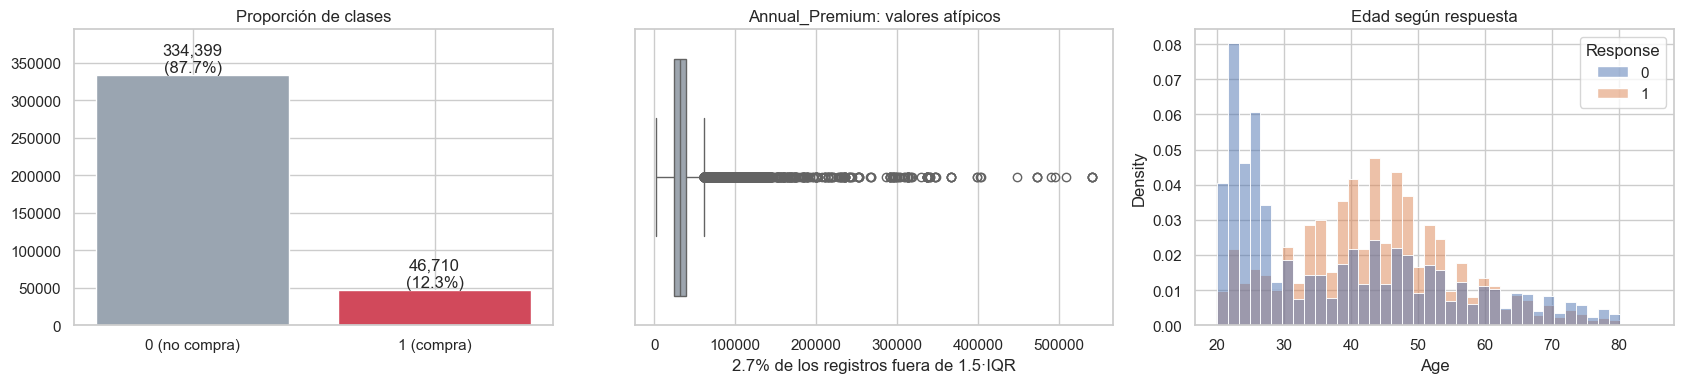

In [4]:
# Grafico 1: proporcion de clases | Grafico 2: atipicos de Annual_Premium | Grafico 3: edad segun respuesta
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
conteo = df.Response.value_counts()
ax[0].bar(["0 (no compra)", "1 (compra)"], conteo.values, color=["#9aa5b1", "#d1495b"])
for i, v in enumerate(conteo.values):
    ax[0].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom")
ax[0].set_title("Proporción de clases"); ax[0].set_ylim(0, conteo.max() * 1.18)

sns.boxplot(x=df.Annual_Premium, ax=ax[1], color="#9aa5b1")
ax[1].set_title("Annual_Premium: valores atípicos")

q1, q3 = df.Annual_Premium.quantile([.25, .75]); iqr = q3 - q1
atip = ((df.Annual_Premium > q3 + 1.5 * iqr) | (df.Annual_Premium < q1 - 1.5 * iqr)).mean()
ax[1].set_xlabel(f"{atip:.1%} de los registros fuera de 1.5·IQR")

sns.histplot(data=df, x="Age", hue="Response", stat="density", common_norm=False, ax=ax[2], bins=40)
ax[2].set_title("Edad según respuesta")
plt.tight_layout(); plt.savefig("resultados/eda_1.png", dpi=130); plt.show()

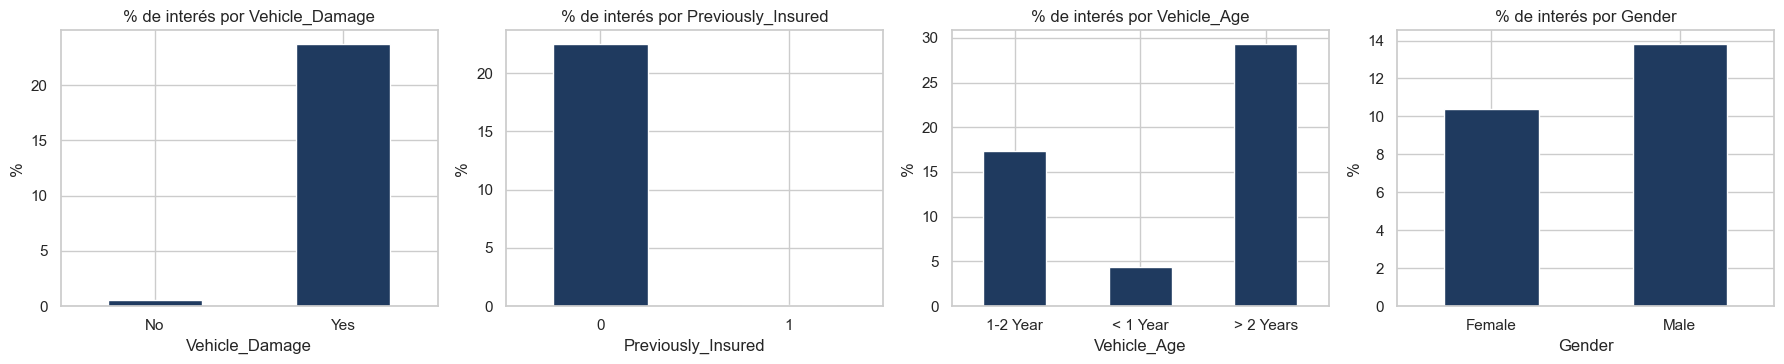

Cardinalidad: {'Region_Code': 53, 'Policy_Sales_Channel': 155}


In [5]:
# Porcentaje de clientes interesados (Response=1) segun algunas variables clave
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, col in zip(ax, ["Vehicle_Damage", "Previously_Insured", "Vehicle_Age", "Gender"]):
    t = df.groupby(col).Response.mean().mul(100)
    t.plot.bar(ax=a, color="#1f3a5f", rot=0); a.set_title(f"% de interés por {col}"); a.set_ylabel("%")
plt.tight_layout(); plt.savefig("resultados/eda_2.png", dpi=130); plt.show()

print("Cardinalidad:", {c: df[c].nunique() for c in ["Region_Code", "Policy_Sales_Channel"]})

**Hallazgos del EDA**
- No hay nulos ni duplicados, pero el pipeline igual incluye imputación por robustez.
- Desbalance fuerte (~12% de positivos): por eso accuracy no sirve y usamos F1 de la clase minoritaria.
- `Annual_Premium` tiene una cola larga con atípicos → se aplica `log1p` y estandarización **dentro del pipeline** (también ayuda a SMOTE, que usa distancias).
- Quienes **ya tienen seguro de vehículo** (`Previously_Insured=1`) casi nunca responden; quienes tuvieron **daño previo** responden mucho más.
- `Region_Code` y `Policy_Sales_Channel` son *códigos* (53 y 155 valores), no cantidades: se codifican con one-hot agrupando las categorías raras (< 1%).

**Decisiones del pipeline (`ColumnTransformer`)**: numéricas (`Age`, `Vintage`, `Annual_Premium`) → imputación mediana + log (solo premium) + escala; binarias (`Gender`, `Vehicle_Damage`) → one-hot con `drop="if_binary"`; categóricas (`Vehicle_Age`, `Region_Code`, `Policy_Sales_Channel`) → imputación + one-hot; `Driving_License` y `Previously_Insured` ya son 0/1.

In [6]:
y = df["Response"]
X = df.drop(columns="Response")

# Partición 80/20 estratificada y con semilla fija. El test se reserva hasta el final.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Train: {len(X_train):,} ({y_train.mean():.2%} positivos) | Test: {len(X_test):,} ({y_test.mean():.2%} positivos)")

# Grupos de columnas segun el tratamiento que reciben
num_log = ["Annual_Premium"]                                   # numerica con cola larga -> log
num = ["Age", "Vintage"]                                       # numericas normales
bin_cat = ["Gender", "Vehicle_Damage"]                         # categoricas binarias
multi_cat = ["Vehicle_Age", "Region_Code", "Policy_Sales_Channel"]  # categoricas con varios valores
pasan = ["Driving_License", "Previously_Insured"]              # ya son 0/1

def make_preprocessor():
    # Devuelve un ColumnTransformer NUEVO cada vez (limpieza + codificacion dentro del pipeline)
    return ColumnTransformer([
        ("num", SkPipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("log", SkPipeline([("imp", SimpleImputer(strategy="median")),
                            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                            ("sc", StandardScaler())]), num_log),
        ("bin", SkPipeline([("imp", SimpleImputer(strategy="most_frequent")),
                            ("oh", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False))]), bin_cat),
        ("cat", SkPipeline([("imp", SimpleImputer(strategy="most_frequent")),
                            ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False))]), multi_cat),
        ("pass", "passthrough", pasan),
    ])

prep_demo = make_preprocessor().fit(X_train)
print("Columnas después del preprocesamiento:", len(prep_demo.get_feature_names_out()))

Train: 304,887 (12.26% positivos) | Test: 76,222 (12.26% positivos)


Columnas después del preprocesamiento: 46


### Diseño de la búsqueda (consideraciones de cómputo)
- La búsqueda de hiperparámetros usa `RandomizedSearchCV` (10 combinaciones, `StratifiedKFold` de 3 folds, métrica **F1 de la clase minoritaria**) sobre una **submuestra estratificada de 30.000 filas** del train.
- SMOTE va como paso del `Pipeline` de `imblearn`, así que en cada fold solo se aplica a la parte de entrenamiento.
- El ganador de cada combinación se **reentrena con todo el train** y recién ahí se mide en train y en test (umbral 0,5).
- Todo con `random_state=42` y `n_jobs=-1`.

In [7]:
# Parametros de la busqueda (por tiempo de computo): submuestra de 30.000 filas, 10 combinaciones, 3 folds
N_SUB, N_ITER, CV_FOLDS = 30_000, 10, 3
# Validacion cruzada estratificada: cada fold mantiene la proporcion de clases
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

# Submuestra estratificada del train (solo para la búsqueda)
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=N_SUB, stratify=y_train, random_state=SEED)
print(f"Submuestra de búsqueda: {len(X_sub):,} filas ({y_sub.mean():.2%} positivos)")

N_NEG, N_POS = (y_train == 0).sum(), (y_train == 1).sum()
SPW = N_NEG / N_POS          # scale_pos_weight de XGBoost (negativos / positivos del train)
print(f"scale_pos_weight = {SPW:.3f}")

MODELOS = ["Árbol de decisión", "Random Forest", "XGBoost", "AdaBoost", "LightGBM"]

def base_estimator(nombre, modo):
    """modo: 'smote' (sin pesos) | 'pesos' (pesos de la tabla) | 'plano' (proporción real: sin SMOTE ni pesos)."""
    w = modo == "pesos"
    if nombre == "Árbol de decisión":
        return DecisionTreeClassifier(class_weight="balanced" if w else None, random_state=SEED)
    if nombre == "Random Forest":
        return RandomForestClassifier(class_weight="balanced" if w else None, random_state=SEED, n_jobs=-1)
    if nombre == "XGBoost":
        return XGBClassifier(scale_pos_weight=SPW if w else 1.0, tree_method="hist", eval_metric="logloss",
                             random_state=SEED, n_jobs=-1)
    if nombre == "AdaBoost":
        return AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, class_weight="balanced" if w else None),
                                  random_state=SEED)
    if nombre == "LightGBM":
        return LGBMClassifier(class_weight="balanced" if w else None, random_state=SEED, n_jobs=-1, verbose=-1)

def build(nombre, modo):
    # Pipeline = limpieza -> (SMOTE solo en modo 'smote') -> modelo
    # Al ir todo dentro del pipeline, en cada fold el preprocesamiento y SMOTE se ajustan solo con el train del fold.
    pasos = [("prep", make_preprocessor())]
    if modo == "smote":
        pasos.append(("smote", SMOTE(random_state=SEED)))
    pasos.append(("model", base_estimator(nombre, modo)))
    return Pipeline(pasos)

# Grillas de hiperparametros (al menos 2 por modelo). El prefijo 'model__' apunta al paso 'model' del pipeline.
GRIDS = {
    "Árbol de decisión": {"model__max_depth": [4, 6, 8, 10, 12], "model__min_samples_leaf": [10, 30, 100, 300],
                          "model__criterion": ["gini", "entropy"]},
    "Random Forest":     {"model__n_estimators": [100, 150], "model__max_depth": [8, 12, 16],
                          "model__min_samples_leaf": [5, 20, 50], "model__max_features": ["sqrt", 0.5]},
    "XGBoost":           {"model__n_estimators": [100, 200, 300], "model__max_depth": [3, 5, 7],
                          "model__learning_rate": [0.05, 0.1, 0.2], "model__subsample": [0.8, 1.0]},
    "AdaBoost":          {"model__n_estimators": [50, 100, 200], "model__learning_rate": [0.1, 0.5, 1.0],
                          "model__estimator__max_depth": [1, 2, 3]},
    "LightGBM":          {"model__n_estimators": [100, 200, 300], "model__num_leaves": [15, 31, 63],
                          "model__learning_rate": [0.05, 0.1], "model__min_child_samples": [20, 50, 100]},
}

def n_comb(grid):
    return int(np.prod([len(v) for v in grid.values()]))

Submuestra de búsqueda: 30,000 filas (12.26% positivos)
scale_pos_weight = 7.159


In [8]:
RESULTADOS, MODELOS_FIT = [], {}

def correr(nombre, modo):
    """Para un modelo y una etapa: busca hiperparametros (CV en la submuestra), reentrena el ganador
    con todo el train, mide train/test y guarda una fila de resultados."""
    etapa = "A (SMOTE)" if modo == "smote" else "B (pesos)"

    # PASO 1: busqueda aleatoria de hiperparametros con CV estratificada, optimizando F1 de la clase minoritaria
    t0 = time.time()
    busq = RandomizedSearchCV(build(nombre, modo), GRIDS[nombre], n_iter=min(N_ITER, n_comb(GRIDS[nombre])),
                              scoring="f1", cv=cv, random_state=SEED, n_jobs=1, refit=False, error_score="raise")
    busq.fit(X_sub, y_sub)
    t_busq = time.time() - t0

    # PASO 2: F1 de cada fold para la mejor combinacion (sirve para ver la estabilidad entre folds)
    i = busq.best_index_
    folds = [busq.cv_results_[f"split{k}_test_score"][i] for k in range(CV_FOLDS)]

    # PASO 3: reentrenar el ganador con TODO el train (la busqueda uso solo la submuestra)
    t1 = time.time()
    modelo = build(nombre, modo).set_params(**busq.best_params_).fit(X_train, y_train)
    t_fit = time.time() - t1

    # PASO 4: predicciones con umbral 0.5 en train y test (el test se usa solo para confirmar)
    p_tr, p_te = modelo.predict_proba(X_train)[:, 1], modelo.predict_proba(X_test)[:, 1]
    yh_tr, yh_te = (p_tr >= .5).astype(int), (p_te >= .5).astype(int)
    # PASO 5: guardar todas las metricas de la combinacion
    fila = {
        "Modelo": nombre, "Etapa": etapa,
        "F1 train": f1_score(y_train, yh_tr), "F1 CV": busq.best_score_, "F1 CV (std)": busq.cv_results_["std_test_score"][i],
        "F1 test": f1_score(y_test, yh_te),
        "Recall test": recall_score(y_test, yh_te), "Precisión test": precision_score(y_test, yh_te),
        "AUC-ROC test": roc_auc_score(y_test, p_te),
        "Tiempo búsqueda (s)": t_busq, "Tiempo reentrenamiento (s)": t_fit,
        "Mejores hiperparámetros": {k.replace("model__", ""): v for k, v in busq.best_params_.items()},
        "F1 por fold": folds,
    }
    fila["Brecha train-test"] = fila["F1 train"] - fila["F1 test"]
    RESULTADOS.append(fila); MODELOS_FIT[(nombre, etapa)] = (modelo, busq.best_params_)
    print(f"{nombre:18s} {etapa:10s} | F1 CV {fila['F1 CV']:.4f} | F1 test {fila['F1 test']:.4f} | "
          f"búsqueda {t_busq:5.0f}s | reentreno {t_fit:5.0f}s")

## 3. Etapa A: 5 modelos con SMOTE
SMOTE como paso del `Pipeline` (solo se aplica a la parte de entrenamiento de cada fold). Sin pesos de clase.

In [9]:
# Etapa A: los 5 modelos con SMOTE dentro del pipeline (cada correr() imprime su resumen)
for m in MODELOS:
    correr(m, "smote")

Árbol de decisión  A (SMOTE)  | F1 CV 0.4245 | F1 test 0.4272 | búsqueda    13s | reentreno     7s


Random Forest      A (SMOTE)  | F1 CV 0.4380 | F1 test 0.4450 | búsqueda    29s | reentreno    84s


XGBoost            A (SMOTE)  | F1 CV 0.4344 | F1 test 0.4422 | búsqueda    16s | reentreno     5s


AdaBoost           A (SMOTE)  | F1 CV 0.4334 | F1 test 0.4324 | búsqueda   127s | reentreno    95s


LightGBM           A (SMOTE)  | F1 CV 0.4327 | F1 test 0.4467 | búsqueda    16s | reentreno     4s


## 4. Etapa B: 5 modelos con pesos ponderados
Sin SMOTE; cada modelo pondera la clase minoritaria según la tabla del enunciado (`class_weight='balanced'`, `scale_pos_weight` = negativos / positivos, y árbol base ponderado en AdaBoost).

In [10]:
# Etapa B: los mismos 5 modelos, sin SMOTE, con pesos para la clase minoritaria
for m in MODELOS:
    correr(m, "pesos")

Árbol de decisión  B (pesos)  | F1 CV 0.4197 | F1 test 0.4339 | búsqueda     5s | reentreno     4s


Random Forest      B (pesos)  | F1 CV 0.4386 | F1 test 0.4441 | búsqueda    14s | reentreno    56s


XGBoost            B (pesos)  | F1 CV 0.4307 | F1 test 0.4372 | búsqueda     9s | reentreno     4s


AdaBoost           B (pesos)  | F1 CV 0.4208 | F1 test 0.4284 | búsqueda    27s | reentreno     4s


LightGBM           B (pesos)  | F1 CV 0.4298 | F1 test 0.4354 | búsqueda    11s | reentreno     2s


## 5. Tabla de las 10 combinaciones y mejor modelo por CV

In [11]:
# Tabla comparativa de las 10 combinaciones, ordenada por F1 de CV (criterio de seleccion)
res = pd.DataFrame(RESULTADOS)
cols =["Modelo", "Etapa", "F1 train", "F1 CV", "F1 CV (std)", "F1 test", "Brecha train-test",
        "Recall test", "Precisión test", "AUC-ROC test", "Tiempo búsqueda (s)"]
tabla = res[cols].sort_values("F1 CV", ascending=False).reset_index(drop=True)
tabla.to_csv("resultados/tabla_10_combinaciones.csv", index=False)
(tabla.style.format({c: "{:.4f}" for c in cols[2:10]} | {"Tiempo búsqueda (s)": "{:.0f}"})
      .background_gradient(subset=["F1 CV"], cmap="Blues").hide(axis="index"))

Modelo,Etapa,F1 train,F1 CV,F1 CV (std),F1 test,Brecha train-test,Recall test,Precisión test,AUC-ROC test,Tiempo búsqueda (s)
Random Forest,B (pesos),0.4707,0.4386,0.0070,0.4441,0.0267,0.8875,0.2961,0.8551,14
Random Forest,A (SMOTE),0.4602,0.4380,0.0088,0.4450,0.0152,0.8196,0.3054,0.8493,29
XGBoost,A (SMOTE),0.4426,0.4344,0.0069,0.4422,0.0003,0.8757,0.2958,0.8524,16
AdaBoost,A (SMOTE),0.4306,0.4334,0.0011,0.4324,-0.0018,0.9059,0.2840,0.8497,127
LightGBM,A (SMOTE),0.4464,0.4327,0.0080,0.4467,-0.0003,0.8295,0.3056,0.8521,16
XGBoost,B (pesos),0.4512,0.4307,0.0021,0.4372,0.0139,0.9106,0.2877,0.8557,9
LightGBM,B (pesos),0.4448,0.4298,0.0065,0.4354,0.0094,0.9175,0.2854,0.8565,11
Árbol de decisión,A (SMOTE),0.4264,0.4245,0.0074,0.4272,-0.0008,0.8066,0.2905,0.8381,13
AdaBoost,B (pesos),0.4281,0.4208,0.0073,0.4284,-0.0003,0.8874,0.2823,0.8269,27
Árbol de decisión,B (pesos),0.4361,0.4197,0.0026,0.4339,0.0023,0.9154,0.2843,0.8524,5


MEJOR POR CV: Random Forest · Etapa B (pesos)
  F1 CV = 0.4386 ± 0.0070 | F1 test = 0.4441 | brecha = 0.0267
  Hiperparámetros: {'n_estimators': 150, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 16}


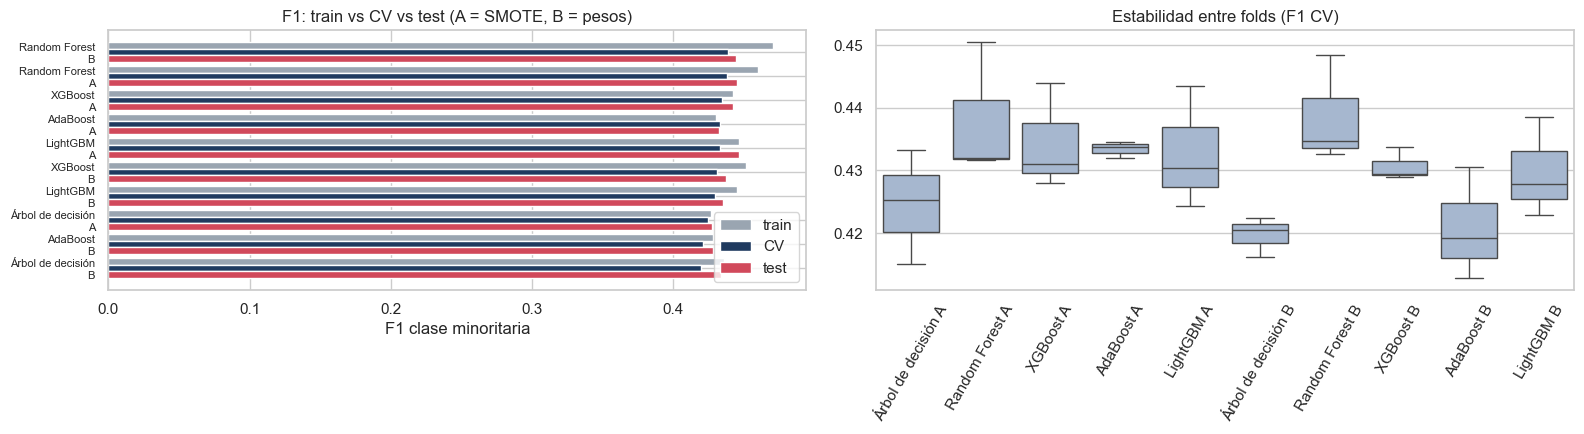

In [12]:
# Mejor modelo: se elige SOLO por la métrica de CV (el test solo confirma)
mejor = res.sort_values("F1 CV", ascending=False).iloc[0]
MEJOR_NOMBRE, MEJOR_ETAPA = mejor["Modelo"], mejor["Etapa"]
print(f"MEJOR POR CV: {MEJOR_NOMBRE} · Etapa {MEJOR_ETAPA}")
print(f"  F1 CV = {mejor['F1 CV']:.4f} ± {mejor['F1 CV (std)']:.4f} | F1 test = {mejor['F1 test']:.4f} | brecha = {mejor['Brecha train-test']:.4f}")
print("  Hiperparámetros:", mejor["Mejores hiperparámetros"])

# Izquierda: F1 en train, CV y test de cada combinacion (la distancia train-test muestra el sobreajuste)
# Derecha: F1 de cada fold de la CV (cajas angostas = modelo estable)
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
r = res.assign(Comb=res.Modelo + "\n" + res.Etapa.str[0]).sort_values("F1 CV")
y_pos = np.arange(len(r)); h = 0.27
ax[0].barh(y_pos + h, r["F1 train"], h, label="train", color="#9aa5b1")
ax[0].barh(y_pos, r["F1 CV"], h, label="CV", color="#1f3a5f")
ax[0].barh(y_pos - h, r["F1 test"], h, label="test", color="#d1495b")
ax[0].set_yticks(y_pos); ax[0].set_yticklabels(r.Comb, fontsize=8); ax[0].set_xlabel("F1 clase minoritaria"); ax[0].legend()
ax[0].set_title("F1: train vs CV vs test (A = SMOTE, B = pesos)")

fold_df = pd.DataFrame({f"{m} {e[0]}": f for m, e, f in zip(res.Modelo, res.Etapa, res["F1 por fold"])})
sns.boxplot(data=fold_df, ax=ax[1], color="#9fb6d6"); ax[1].tick_params(axis="x", rotation=60)
ax[1].set_title("Estabilidad entre folds (F1 CV)")
plt.tight_layout(); plt.savefig("resultados/comparacion_10.png", dpi=130); plt.show()

In [13]:
# SMOTE vs pesos: promedio de cada metrica por etapa (A = SMOTE, B = pesos)
res.groupby("Etapa")[["F1 CV", "F1 test", "Recall test", "Precisión test", "AUC-ROC test", "Brecha train-test", "Tiempo búsqueda (s)"]].mean().round(4)

,F1 CV,F1 test,Recall test,Precisión test,AUC-ROC test,Brecha train-test,Tiempo búsqueda (s)
Etapa,,,,,,,
A (SMOTE),0.4326,0.4387,0.8475,0.2963,0.8483,0.0025,40.2115
B (pesos),0.4279,0.4358,0.9037,0.2872,0.8493,0.0104,13.2060


**Justificación del mejor modelo**
- El mejor por **F1 CV** es **Random Forest con pesos (Etapa B)**: F1 CV = 0,4386 ± 0,007, F1 test = 0,4441 (el test confirma). Le siguen de cerca Random Forest+SMOTE (0,4380), XGBoost+SMOTE (0,4344), AdaBoost+SMOTE y LightGBM+SMOTE; las diferencias entre los 5 primeros son menores a la desviación entre folds, es decir, **estadísticamente cercanas**.
- **Sobreajuste:** la brecha train–test del ganador es 0,027, la más alta del grupo pero baja en términos absolutos (los hiperparámetros acotan la profundidad). XGBoost+SMOTE y LightGBM+SMOTE tienen brecha ≈ 0 y casi el mismo F1: son alternativas más estables si se priorizara robustez.
- **Estabilidad:** la desviación del F1 entre folds es baja (~0,007), no hay folds anómalos (boxplot).
- **SMOTE vs pesos:** el F1 promedio es casi igual (0,4326 vs 0,4279 en CV). SMOTE da brechas menores y precisión algo mayor, pero **la búsqueda tarda ~3 veces más** (39 s vs 13 s promedio, y mucho más con datos completos). Los pesos logran un rendimiento equivalente con menos cómputo y sin fabricar datos sintéticos, por lo que **convienen más en esta base** (grande y con variables mayormente categóricas, donde interpolar puntos sintéticos tiene poco sentido).
- Ambas estrategias *inflan* la probabilidad de la clase minoritaria (no están en escala real); por eso en la Parte 2 se reentrena con la proporción real.

## 6. Matriz de costos en dinero

Todos los montos son **supuestos declarados** (USD por cliente), con justificación de negocio:

| | Costo | Justificación (supuesto) |
|---|---|---|
| **FP** (contactar a quien no compra) | **US$ 5** | Llamada de un agente de call center (~8–10 min de trabajo) + costo de telefonía. |
| **FN** (no contactar a quien sí compraba) | **US$ 50** | Margen de utilidad perdido de una póliza vendida (prima anual × margen) + valor de vida del cliente. |
| TP / TN | 0 | Decisión correcta; el costo del contacto de un TP se considera parte de la venta. |

La razón FN/FP = 10 es un supuesto; la **sección 8** muestra qué pasa si es otra.

**Costo total** = FP · C_FP + FN · C_FN
**Umbral teórico:** clasificar como positivo si P(1 | x) ≥ p* = C_FP / (C_FP + C_FN)

In [14]:
# Costos de negocio (supuestos declarados arriba)
C_FP, C_FN = 5.0, 50.0
# Umbral teorico (Elkan, 2001): contactar si P(1|x) >= C_FP / (C_FP + C_FN)
P_STAR = C_FP / (C_FP + C_FN)
print(f"p* = {C_FP} / ({C_FP} + {C_FN}) = {P_STAR:.4f}")

def costo_total(y_true, y_pred, c_fp=C_FP, c_fn=C_FN):
    # Costo en dinero = (cantidad de FP) x C_FP + (cantidad de FN) x C_FN
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    fp = ((y_pred == 1) & (y_true == 0)).sum()
    fn = ((y_pred == 0) & (y_true == 1)).sum()
    return fp * c_fp + fn * c_fn

def evaluar(y_true, y_pred, nombre):
    # Resume una estrategia: matriz de confusion, recall, precision y costos en dinero
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"Estrategia": nombre, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Recall": tp / (tp + fn), "Precisión": tp / (tp + fp) if (tp + fp) else 0.0,
            "Costo FP": fp * C_FP, "Costo FN": fn * C_FN, "Costo total": fp * C_FP + fn * C_FN}

p* = 5.0 / (5.0 + 50.0) = 0.0909


### 6.1 ¿De dónde sale p*? Costo esperado de cada decisión
Para un cliente con probabilidad p de comprar, hay dos decisiones posibles:

| Decisión | Nos equivocamos si… | Costo esperado |
|---|---|---|
| **No contactar** | el cliente sí habría comprado (FN) | p · C_FN |
| **Contactar** | el cliente no compra (FP) | (1 − p) · C_FP |

Conviene contactar cuando contactar cuesta menos en promedio:

(1 − p) · C_FP ≤ p · C_FN  ⟺  p ≥ C_FP / (C_FP + C_FN) = p*

**Ejemplo con nuestros costos:** un cliente con p = 0,15 → no contactar cuesta 0,15·50 = 7,5 y contactar cuesta 0,85·5 = 4,25. Se contacta, **aunque su probabilidad sea mucho menor que 0,5**. El umbral 0,5 solo es óptimo cuando C_FP = C_FN.

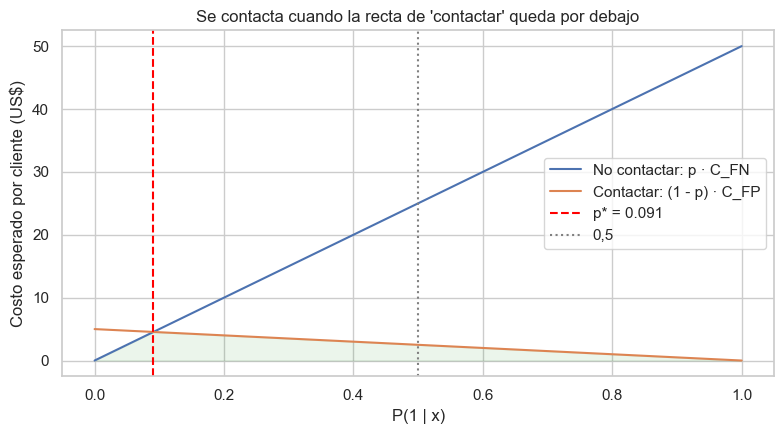

In [15]:
# Costo esperado por cliente de cada decision segun su probabilidad p
pp = np.linspace(0, 1, 201)
plt.figure(figsize=(8, 4.5))
plt.plot(pp, pp * C_FN, label="No contactar: p · C_FN")
plt.plot(pp, (1 - pp) * C_FP, label="Contactar: (1 - p) · C_FP")
plt.axvline(P_STAR, ls="--", color="red", label=f"p* = {P_STAR:.3f}")
plt.axvline(0.5, ls=":", color="gray", label="0,5")
plt.fill_between(pp, 0, np.minimum(pp * C_FN, (1 - pp) * C_FP), color="green", alpha=0.08)  # costo de la mejor decision
plt.xlabel("P(1 | x)"); plt.ylabel("Costo esperado por cliente (US$)")
plt.title("Se contacta cuando la recta de 'contactar' queda por debajo")
plt.legend(); plt.tight_layout(); plt.savefig("resultados/derivacion_pstar.png", dpi=130); plt.show()

## 7. Umbral teórico, empírico y ahorro (comparación en test)

**Probabilidades en escala real.** SMOTE y los pesos inflan la probabilidad de la clase minoritaria; si además bajáramos el umbral, contaríamos el efecto dos veces. Por eso el mejor modelo se **reentrena con la proporción real** (sin SMOTE ni pesos) y con sus mismos hiperparámetros.

El **umbral empírico** se busca con `TunedThresholdClassifierCV` minimizando el costo en dinero, usando **solo el train** (validación cruzada).

In [16]:
# 1) Reentrenar el mejor modelo con la proporción real (sin SMOTE ni pesos) y mismos hiperparámetros
_, mejores_params = MODELOS_FIT[(MEJOR_NOMBRE, MEJOR_ETAPA)]
modelo_real = build(MEJOR_NOMBRE, "plano").set_params(**mejores_params)

# 2) Umbral empírico: minimiza costo en dinero, validación cruzada solo sobre el train
scorer_costo = make_scorer(costo_total, greater_is_better=False, response_method="predict")
t0 = time.time()
tuned = TunedThresholdClassifierCV(modelo_real, scoring=scorer_costo, response_method="predict_proba",
                                   thresholds=np.linspace(0.01, 0.99, 197), cv=cv, refit=True, n_jobs=1,
                                   random_state=SEED)
tuned.fit(X_train, y_train)
print(f"Tiempo: {time.time()-t0:.0f}s")
U_EMP = float(tuned.best_threshold_)
modelo_final = tuned.estimator_          # pipeline reentrenado con todo el train, proporción real
print(f"Umbral teórico p* = {P_STAR:.4f}")
print(f"Umbral empírico   = {U_EMP:.4f}")

Tiempo: 146s
Umbral teórico p* = 0.0909
Umbral empírico   = 0.0850


In [17]:
# Probabilidades en escala real sobre el test (el test se usa recien ahora, para comparar)
proba_test = modelo_final.predict_proba(X_test)[:, 1]
y_te = y_test.to_numpy()

# Modelo con pesos de la Etapa B (mismo algoritmo), con umbral 0.5
mod_B, _ = MODELOS_FIT[(MEJOR_NOMBRE, "B (pesos)")]
proba_pesos = mod_B.predict_proba(X_test)[:, 1]

# Estrategias a comparar: (nombre, prediccion 0/1)
estrategias = [
    ("No hacer nada (todo 0)",           np.zeros_like(y_te)),
    ("Contactar a todos (todo 1)",       np.ones_like(y_te)),
    ("Umbral 0,5 (modelo real)",         (proba_test >= 0.5).astype(int)),
    (f"Umbral teórico p* = {P_STAR:.3f}", (proba_test >= P_STAR).astype(int)),
    (f"Umbral empírico = {U_EMP:.3f}",   (proba_test >= U_EMP).astype(int)),
    (f"Modelo con pesos (Etapa B, 0,5)", (proba_pesos >= 0.5).astype(int)),
]
comp = pd.DataFrame([evaluar(y_te, yh, n) for n, yh in estrategias])
costo_05 = comp.loc[comp.Estrategia.str.startswith("Umbral 0,5"), "Costo total"].iloc[0]
comp["Ahorro vs umbral 0,5"] = costo_05 - comp["Costo total"]
comp["Ahorro %"] = comp["Ahorro vs umbral 0,5"] / costo_05
comp.to_csv("resultados/comparacion_umbrales_test.csv", index=False)
(comp.style.format({"Recall": "{:.3f}", "Precisión": "{:.3f}", "Costo FP": "${:,.0f}", "Costo FN": "${:,.0f}",
                    "Costo total": "${:,.0f}", "Ahorro vs umbral 0,5": "${:,.0f}", "Ahorro %": "{:.1%}",
                    "TN": "{:,}", "FP": "{:,}", "FN": "{:,}", "TP": "{:,}"}).hide(axis="index"))

Estrategia,TN,FP,FN,TP,Recall,Precisión,Costo FP,Costo FN,Costo total,"Ahorro vs umbral 0,5",Ahorro %
No hacer nada (todo 0),"66,880",0,"9,342",0,0.000,0.000,$0,"$467,100","$467,100","$-4,535",-1.0%
Contactar a todos (todo 1),0,"66,880",0,"9,342",1.000,0.123,"$334,400",$0,"$334,400","$128,165",27.7%
"Umbral 0,5 (modelo real)","66,767",113,"9,240",102,0.011,0.474,$565,"$462,000","$462,565",$0,0.0%
Umbral teórico p* = 0.091,"42,298","24,582",382,"8,960",0.959,0.267,"$122,910","$19,100","$142,010","$320,555",69.3%
Umbral empírico = 0.085,"41,829","25,051",334,"9,008",0.964,0.264,"$125,255","$16,700","$141,955","$320,610",69.3%
"Modelo con pesos (Etapa B, 0,5)","47,173","19,707","1,051","8,291",0.887,0.296,"$98,535","$52,550","$151,085","$311,480",67.3%


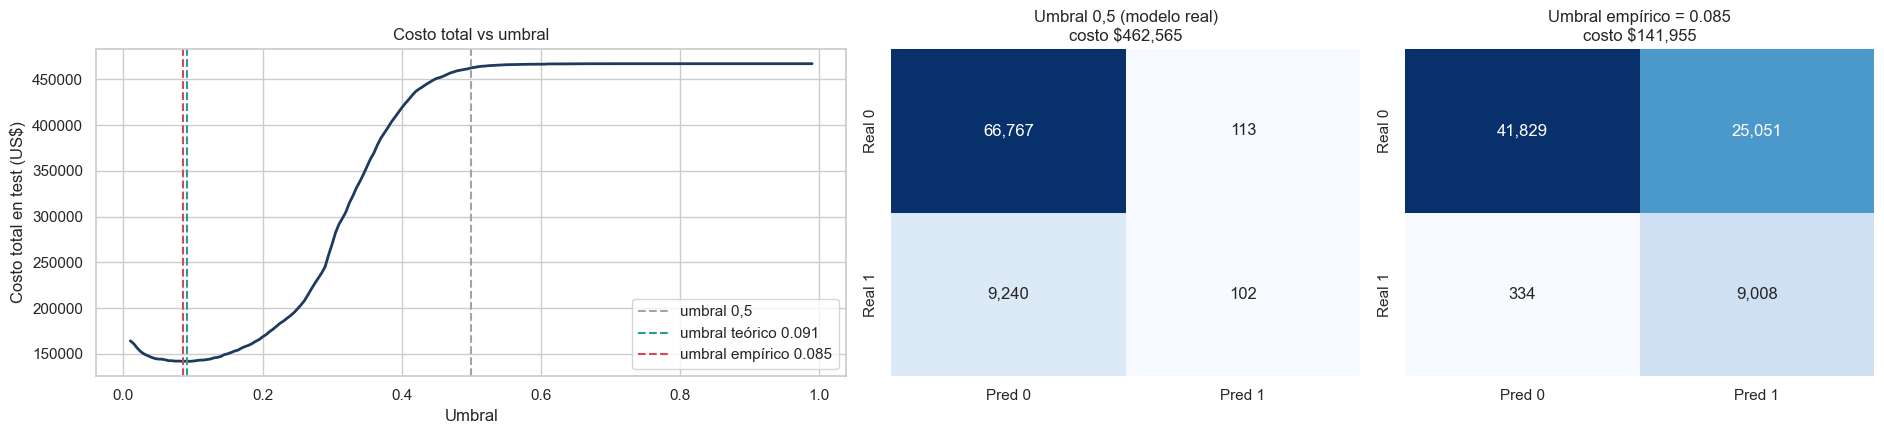

In [18]:
# Izquierda: curva de costo total vs umbral en test, con 0,5, teorico y empirico marcados
# Derecha: matrices de confusion del umbral 0,5 y del empirico, con su costo total en dinero
grid =np.linspace(0.01, 0.99, 197)
costos_curva = [costo_total(y_te, (proba_test >= t).astype(int)) for t in grid]

fig, ax = plt.subplots(1, 3, figsize=(19, 4.5), gridspec_kw={"width_ratios": [1.6, 1, 1]})
ax[0].plot(grid, costos_curva, color="#1f3a5f", lw=2)
for t, c, lab in [(0.5, "#9aa5b1", "0,5"), (P_STAR, "#2a9d8f", f"teórico {P_STAR:.3f}"), (U_EMP, "#d1495b", f"empírico {U_EMP:.3f}")]:
    ax[0].axvline(t, color=c, ls="--", label=f"umbral {lab}")
ax[0].set_xlabel("Umbral"); ax[0].set_ylabel("Costo total en test (US$)"); ax[0].legend(); ax[0].set_title("Costo total vs umbral")
for a, (n, yh) in zip(ax[1:], [estrategias[2], estrategias[4]]):
    cm = confusion_matrix(y_te, yh, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["Real 0", "Real 1"])
    a.set_title(n + f"\ncosto ${costo_total(y_te, yh):,.0f}")
plt.tight_layout(); plt.savefig("resultados/costo_vs_umbral.png", dpi=130); plt.show()

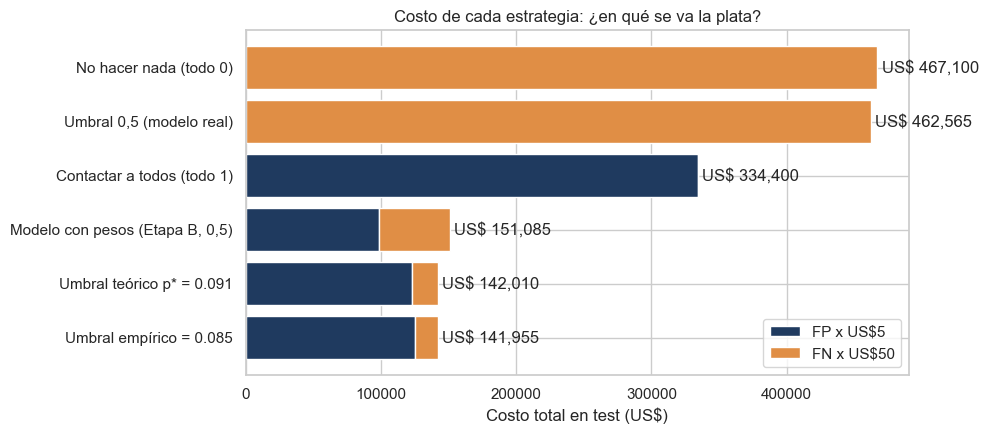

In [19]:
# Desglose del costo en dolares: gasto en contactos inutiles (FP) vs venta perdida (FN)
orden = comp.sort_values("Costo total")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(orden.Estrategia, orden["Costo FP"], color="#1f3a5f", label=f"FP x US${C_FP:,.0f}")
ax.barh(orden.Estrategia, orden["Costo FN"], left=orden["Costo FP"], color="#e08e45", label=f"FN x US${C_FN:,.0f}")
for i, v in enumerate(orden["Costo total"]):
    ax.text(v + 3000, i, f"US$ {v:,.0f}", va="center")
ax.set_xlabel("Costo total en test (US$)"); ax.set_title("Costo de cada estrategia: ¿en qué se va la plata?")
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig("resultados/desglose_costo.png", dpi=130); plt.show()

**Umbrales sobre la curva ROC y recta de iso-costo.** Cada punto de la ROC es un umbral distinto del *mismo* modelo. Con P positivos y N negativos en test:

Costo = C_FN · P · (1 − TPR) + C_FP · N · FPR

Los puntos de igual costo forman rectas de pendiente m = (C_FP · N) / (C_FN · P). El mejor umbral es donde la recta de iso-costo **toca** la ROC más arriba y a la izquierda.

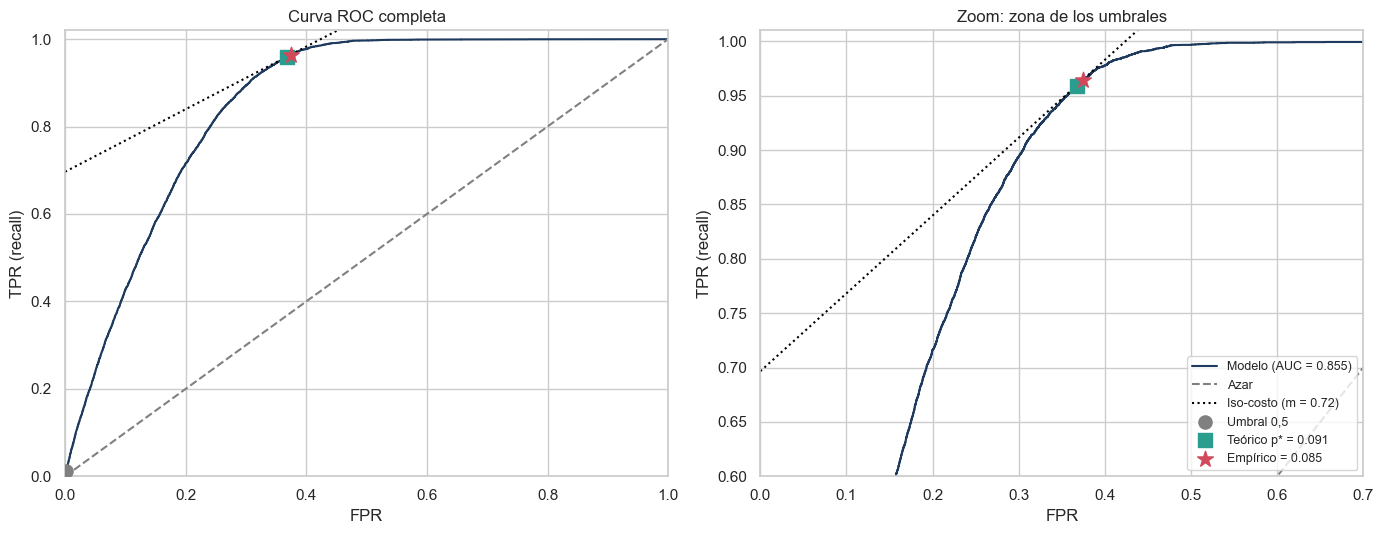

In [20]:
# Curva ROC del modelo final (probabilidades en escala real)
fpr, tpr, thr = roc_curve(y_te, proba_test, drop_intermediate=False)
P_te, N_te = (y_te == 1).sum(), (y_te == 0).sum()
m = (C_FP * N_te) / (C_FN * P_te)                          # pendiente de la recta de iso-costo
k = np.argmin(C_FN * P_te * (1 - tpr) + C_FP * N_te * fpr) # punto de la ROC con minimo costo en test

def punto(y_pred):
    # (FPR, TPR) de una decision concreta
    tn, fp, fn, tp = confusion_matrix(y_te, y_pred, labels=[0, 1]).ravel()
    return fp / (fp + tn), tp / (tp + fn)

xs = np.linspace(0, 1, 50)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, tit in zip(ax, ["Curva ROC completa", "Zoom: zona de los umbrales"]):
    a.plot(fpr, tpr, color="#1f3a5f", label=f"Modelo (AUC = {roc_auc_score(y_te, proba_test):.3f})")
    a.plot([0, 1], [0, 1], "--", color="gray", label="Azar")
    a.plot(xs, tpr[k] + m * (xs - fpr[k]), ":", color="black", label=f"Iso-costo (m = {m:.2f})")
    a.scatter(*punto((proba_test >= 0.5).astype(int)), s=90, color="gray", zorder=3, label="Umbral 0,5")
    a.scatter(*punto((proba_test >= P_STAR).astype(int)), s=90, marker="s", color="#2a9d8f", zorder=3, label=f"Teórico p* = {P_STAR:.3f}")
    a.scatter(*punto((proba_test >= U_EMP).astype(int)), s=140, marker="*", color="#d1495b", zorder=3, label=f"Empírico = {U_EMP:.3f}")
    a.set_xlabel("FPR"); a.set_ylabel("TPR (recall)"); a.set_title(tit)
ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1.02)
ax[1].set_xlim(0, 0.7); ax[1].set_ylim(0.6, 1.01); ax[1].legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig("resultados/roc_isocosto.png", dpi=130); plt.show()

In [21]:
# Escalar el ahorro a una campaña real: ahorro por cliente (test) x tamaño de la cartera
ahorro_cliente = comp.loc[comp.Estrategia.str.startswith("Umbral empírico"), "Ahorro vs umbral 0,5"].iloc[0] / len(y_te)
for cartera in [100_000, 1_000_000]:
    print(f"Cartera de {cartera:>9,} clientes: ahorro estimado de US$ {ahorro_cliente * cartera:,.0f} (umbral empírico vs 0,5)")
print(f"(Ahorro por cliente: US$ {ahorro_cliente:.2f})")

Cartera de   100,000 clientes: ahorro estimado de US$ 420,627 (umbral empírico vs 0,5)
Cartera de 1,000,000 clientes: ahorro estimado de US$ 4,206,266 (umbral empírico vs 0,5)
(Ahorro por cliente: US$ 4.21)


In [22]:
# Revisión de sesgos: ¿el modelo trata distinto a algún grupo? (umbral empírico)
yh_emp = (proba_test >= U_EMP).astype(int)
aux = X_test.assign(y=y_te, pred=yh_emp, grupo_edad=pd.cut(X_test.Age, [0, 30, 45, 60, 100], labels=["<30", "30-44", "45-59", "60+"]))
def resumen(g):
    return pd.Series({"n": len(g), "% contactados": g.pred.mean(), "Recall": recall_score(g.y, g.pred), "Precisión": precision_score(g.y, g.pred, zero_division=0)})
print(aux.groupby("Gender").apply(resumen).round(3), "\n")
print(aux.groupby("grupo_edad", observed=True).apply(resumen).round(3))

              n  % contactados  Recall  Precisión
Gender                                           
Female  34913.0          0.381   0.946      0.254
Male    41309.0          0.503   0.976      0.271 

                  n  % contactados  Recall  Precisión
grupo_edad                                           
<30         32320.0          0.208   0.852      0.181
30-44       19231.0          0.631   0.984      0.331
45-59       16115.0          0.650   0.987      0.284
60+          8556.0          0.552   0.982      0.170


**Lectura de resultados (test, 76.222 clientes, C_FP = US$ 5, C_FN = US$ 50)**
- Con el umbral 0,5 el modelo en escala real casi no contacta a nadie (recall 1%): costo US$ 462.565, prácticamente igual a *no hacer nada* (US$ 467.100). Maximizar F1 o usar 0,5 **no sirve** cuando un FN cuesta 10 veces un FP.
- **Umbral teórico** p* = 0,091 → costo US$ 142.010 (ahorro US$ 320.555, 69% vs 0,5). **Umbral empírico** (elegido solo con el train) = 0,085 → US$ 141.955 (ahorro US$ 320.610). Ambos umbrales son casi idénticos, señal de que las probabilidades en escala real están bien calibradas.
- El **modelo con pesos a 0,5** cuesta US$ 151.085: ahorra US$ 311.480 vs 0,5, pero queda ~US$ 9.000 sobre el umbral empírico: los pesos dan un buen punto de operación, pero no el óptimo para estos costos.
- *Contactar a todos* (US$ 334.400) es mejor que no hacer nada, pero el modelo con umbral óptimo lo mejora en un 57%.
- **Sesgos y privacidad:** con el umbral óptimo se contacta al 50% de los hombres y al 38% de las mujeres, y solo al 21% de los menores de 30 años (su recall baja a 0,85 y la precisión a 0,18). El modelo usa `Gender` y `Age`, así que podría discriminar en la oferta de seguros; se recomienda monitorear por grupo y evaluar excluir `Gender`. La base es pública y anonimizada; no se publican datos personales.

## 8. Sensibilidad a la razón FN/FP
Fijamos C_FP = US$ 5 y variamos C_FN para que la razón FN/FP tome varios valores (incluye el caso base 10). El umbral empírico de cada escenario se busca **solo con probabilidades fuera de muestra del train** (validación cruzada) y su costo se mide en test.

In [23]:
# Probabilidades fuera de muestra (OOF) del train: cada cliente se predice con un modelo que NO lo vio.
# Sirven para elegir umbrales empiricos sin tocar el test.
t0 = time.time()
proba_oof = cross_val_predict(clone(modelo_real), X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
print(f"Probabilidades OOF del train listas ({time.time()-t0:.0f}s)")
y_tr = y_train.to_numpy()

grid_s = np.linspace(0.01, 0.99, 197)
filas, curvas = [], {}
for razon in [2, 5, 10, 20, 50]:
    cfn = C_FP * razon                                   # C_FP fijo; se varia C_FN
    p_teo = C_FP / (C_FP + cfn)                          # umbral teorico del escenario
    # umbral empirico: el que minimiza el costo en las probabilidades OOF del train
    c_tr = [costo_total(y_tr, (proba_oof >= t).astype(int), C_FP, cfn) for t in grid_s]
    u_emp = grid_s[int(np.argmin(c_tr))]
    # costo en test de un umbral cualquiera, con los costos del escenario
    f = lambda u: costo_total(y_te, (proba_test >= u).astype(int), C_FP, cfn)
    curvas[razon] = [f(t) for t in grid_s]
    filas.append({"Razón FN/FP": razon, "C_FN": cfn, "Umbral teórico": p_teo, "Umbral empírico": u_emp,
                  "Costo @0,5": f(0.5), "Costo @teórico": f(p_teo), "Costo @empírico": f(u_emp),
                  "Costo modelo pesos (B)": costo_total(y_te, (proba_pesos >= 0.5).astype(int), C_FP, cfn),
                  "Costo no hacer nada": costo_total(y_te, np.zeros_like(y_te), C_FP, cfn),
                  "Ahorro @empírico vs 0,5": f(0.5) - f(u_emp)})
sens = pd.DataFrame(filas)
sens.to_csv("resultados/sensibilidad.csv", index=False)
(sens.style.format({"Umbral teórico": "{:.3f}", "Umbral empírico": "{:.3f}", "C_FN": "${:,.0f}", "Costo @0,5": "${:,.0f}",
                    "Costo @teórico": "${:,.0f}", "Costo @empírico": "${:,.0f}", "Costo modelo pesos (B)": "${:,.0f}", "Costo no hacer nada": "${:,.0f}",
                    "Ahorro @empírico vs 0,5": "${:,.0f}"}).hide(axis="index"))

Probabilidades OOF del train listas (90s)


Razón FN/FP,C_FN,Umbral teórico,Umbral empírico,"Costo @0,5",Costo @teórico,Costo @empírico,Costo modelo pesos (B),Costo no hacer nada,"Ahorro @empírico vs 0,5"
2,$10,0.333,0.325,"$92,965","$86,980","$87,160","$109,045","$93,420","$5,805"
5,$25,0.167,0.165,"$231,565","$124,755","$124,550","$124,810","$233,550","$107,015"
10,$50,0.091,0.085,"$462,565","$142,010","$141,955","$151,085","$467,100","$320,610"
20,$100,0.048,0.045,"$924,565","$153,525","$153,510","$203,635","$934,200","$771,055"
50,$250,0.020,0.015,"$2,310,565","$170,045","$168,275","$361,285","$2,335,500","$2,142,290"


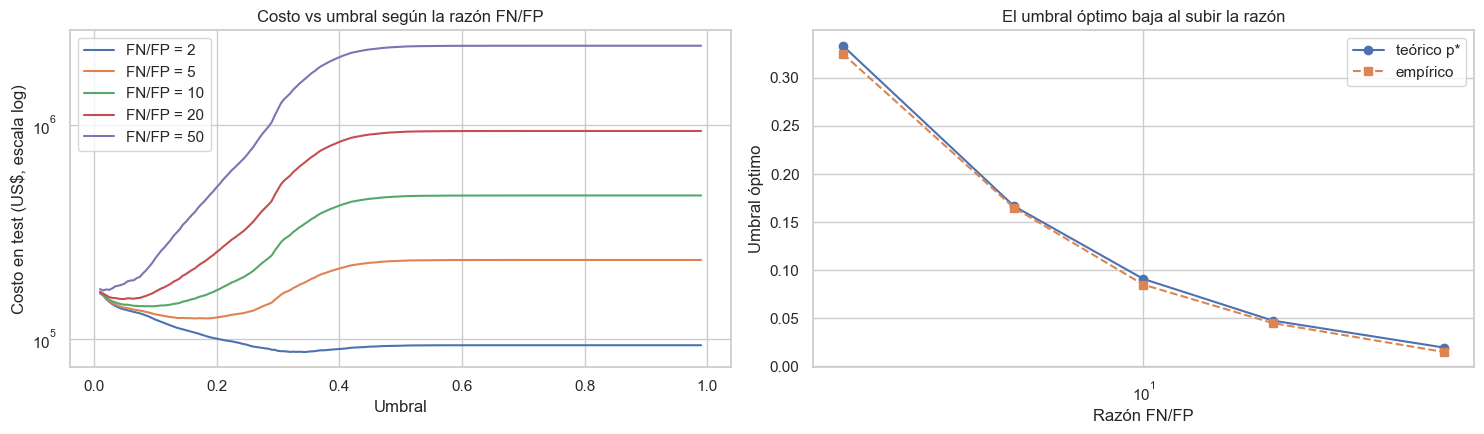

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for razon, c in curvas.items():
    ax[0].plot(grid_s, c, label=f"FN/FP = {razon}")
ax[0].set_yscale("log"); ax[0].set_xlabel("Umbral"); ax[0].set_ylabel("Costo en test (US$, escala log)"); ax[0].legend(); ax[0].set_title("Costo vs umbral según la razón FN/FP")
ax[1].plot(sens["Razón FN/FP"], sens["Umbral teórico"], "o-", label="teórico p*")
ax[1].plot(sens["Razón FN/FP"], sens["Umbral empírico"], "s--", label="empírico")
ax[1].set_xscale("log"); ax[1].set_xlabel("Razón FN/FP"); ax[1].set_ylabel("Umbral óptimo"); ax[1].legend(); ax[1].set_title("El umbral óptimo baja al subir la razón")
plt.tight_layout(); plt.savefig("resultados/sensibilidad.png", dpi=130); plt.show()

**Lectura.** A mayor razón FN/FP, menor el umbral óptimo (conviene contactar a más gente) y mayor el ahorro frente al umbral 0,5. Si FN/FP fuera cercano a 1, p* se acerca a 0,5 y el ahorro se reduce. El umbral teórico y el empírico quedan muy cerca en todos los escenarios.

**Solo importa la razón.** p* depende únicamente de FN/FP: usar (US$ 5, US$ 50) o (US$ 20, US$ 200) da el mismo umbral y las mismas decisiones; los dólares solo sirven para comunicar el impacto a la gerencia.

**Limitación.** Todo se evaluó en **una sola partición** train/test (con 76.222 clientes de test y ~9.300 positivos, la diferencia entre p* y el umbral empírico es de pocos cientos de dólares, es decir, ruido). Con una partición distinta esa diferencia podría cambiar de signo; lo robusto es la conclusión general (bajar el umbral ahorra ≈ 69%).

## 9. Dashboard (exportación para Streamlit)
Se exportan las probabilidades **en escala real** del test (`y_test`, `proba`) a `dashboard_data/predicciones_test.csv`. La app (`app.py`) permite modificar C_FP y C_FN, ver cómo se mueve p*, mover el umbral a mano, ver la curva de costo, la matriz de confusión con costos, los indicadores y la curva ROC con recta de iso-costo.

Para correrlo localmente: `streamlit run app.py`.

In [25]:
# CSV que lee app.py: etiqueta real + probabilidad en escala real (+ la del modelo con pesos, de referencia)
# Tambien se guarda el modelo final con joblib, como pide el enunciado.
export = pd.DataFrame({"y_test": y_te, "proba": proba_test.round(6), "proba_pesos_etapa_B": proba_pesos.round(6)})
export.to_csv("dashboard_data/predicciones_test.csv", index=False)
joblib.dump(modelo_final, "models/mejor_modelo.joblib", compress=3)
joblib.dump({"modelo": MEJOR_NOMBRE, "etapa": MEJOR_ETAPA, "hiperparametros": mejores_params, "umbral_empirico": U_EMP,
             "umbral_teorico": P_STAR, "C_FP": C_FP, "C_FN": C_FN}, "models/metadata.joblib")
print("Exportado:", export.shape, "| tamaño modelo:", round(os.path.getsize("models/mejor_modelo.joblib") / 1e6, 1), "MB")
export.head()

Exportado: (76222, 3) | tamaño modelo: 13.9 MB


,y_test,proba,proba_pesos_etapa_B
0,1,0.468479,0.806143
1,0,0.341516,0.690018
2,0,0.270125,0.634059
3,1,0.301187,0.752080
4,1,0.405874,0.785796


## Conclusiones
1. Se comparó 5 modelos × 2 estrategias (10 combinaciones) con pipeline sin fuga de datos y búsqueda de hiperparámetros con CV estratificada; el mejor se eligió por F1 CV.
2. Optimizar F1 no equivale a minimizar costo: al asignar dinero a FP y FN, el umbral 0,5 deja de ser el mejor y el umbral por costo genera un **ahorro** medible en test.
3. El umbral óptimo depende de los costos de negocio; el dashboard permite explorarlos en vivo.
4. **Limitaciones:** los costos son supuestos; la búsqueda se hizo en una submuestra de 30.000 filas; el modelo usa variables sensibles (género, edad) y debe monitorearse por grupo.